# DS603 Group Project — Full Analysis

**Monte Carlo Evaluation of VaR and CVaR Estimators Using Real US Equity Return Data**

**Student:** Tan Kok Yong (01426300) · DS603 Probability for Data Science · SMU MDSE

This notebook combines all five analysis notebooks into a single end-to-end script.
Run cells top to bottom. Requires a WRDS account and the project `src/` modules on `PROJECT_ROOT`.

| Section | Content |
|---|---|
| 1 | Data pull and cleaning (WRDS CRSP) |
| 2 | Descriptive analysis and distribution fitting |
| 3 | VaR and CVaR estimator implementation and validation |
| 4 | Monte Carlo finite-sample study (bias, SD, RMSE) |
| 5 | Rolling-window backtesting and Kupiec test |

> **Data ethics:** raw CRSP extracts are saved to `data/raw/` (gitignored). Do **not** commit licensed data.

In [1]:
# Install required packages (run once per Colab session)
!pip install -q wrds pandas numpy scipy statsmodels matplotlib seaborn pyarrow

import sys, os, json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.gridspec as gridspec
import seaborn as sns
from scipy import stats
from scipy.stats import jarque_bera, skew, kurtosis

from google.colab import drive
drive.mount('/content/drive')
PROJECT_ROOT = '/content/drive/MyDrive/DS603_Project'
sys.path.insert(0, PROJECT_ROOT)

RAW_DIR        = os.path.join(PROJECT_ROOT, 'data', 'raw')
PROCESSED_DIR  = os.path.join(PROJECT_ROOT, 'data', 'processed')
FIG_DIR        = os.path.join(PROJECT_ROOT, 'outputs', 'figures')
TAB_DIR        = os.path.join(PROJECT_ROOT, 'outputs', 'tables')
MDL_DIR        = os.path.join(PROJECT_ROOT, 'models')
for d in (RAW_DIR, PROCESSED_DIR, FIG_DIR, TAB_DIR, MDL_DIR):
    os.makedirs(d, exist_ok=True)

sns.set_theme(style='whitegrid', context='notebook')

# -- Shared constants --
TICKERS        = ['JPM', 'AAPL', 'TSLA']
ALPHAS         = (0.95, 0.99)
PERMNOS        = {'JPM': 47896, 'AAPL': 14593, 'TSLA': 93436}
START_DATE     = '2015-01-01'
END_DATE       = '2024-12-31'

CALM_START     = pd.Timestamp('2017-01-01')
CALM_END       = pd.Timestamp('2019-12-31')
STRESSED_START = pd.Timestamp('2020-02-01')
STRESSED_END   = pd.Timestamp('2020-12-31')

WINDOW         = 250    # rolling estimation window (trading days)
ALPHA          = 0.99   # primary VaR confidence level

COLORS     = {'full': 'steelblue', 'calm': 'seagreen', 'stressed': 'crimson'}
EST_LABELS = {'hist': 'Historical', 'norm': 'Parametric Normal', 't': 'Parametric t'}
EST_COLORS = {'hist': 'steelblue', 'norm': 'crimson', 't': 'seagreen'}
EST_MARKERS= {'hist': 'o', 'norm': 's', 't': '^'}

print('Setup complete. PROJECT_ROOT:', PROJECT_ROOT)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.3/4.3 MB 52.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 51.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 623.8/623.8 kB 26.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 70.2 MB/s eta 0:00:00
Mounted at /content/drive
Setup complete. PROJECT_ROOT: /content/drive/MyDrive/DS603_Project


In [2]:
# Import project source modules
from src.estimators import (
    historical_var, historical_cvar,
    parametric_normal_var, parametric_normal_cvar,
    parametric_t_var, parametric_t_cvar,
    fit_student_t, true_t_var, true_t_cvar,
    compute_all_estimators,
)
from src.simulation import run_monte_carlo, SAMPLE_SIZES, N_REPS, SEED

print(f'MC settings: seed={SEED}, n_reps={N_REPS:,}, sample_sizes={SAMPLE_SIZES}')


MC settings: seed=42, n_reps=1,000, sample_sizes=(60, 250, 1000)


---

## Section 01 — Data Pull and Cleaning


## 2. Connect to WRDS and pull data

In [3]:
import wrds

# wrds.Connection() reads credentials from ~/.pgpass or prompts interactively.
# In Colab, you will be prompted for your WRDS username and password.
conn = wrds.Connection()
print('Connected to WRDS.')

Enter your WRDS username [root]:kyongtan
Enter your password:··········
WRDS recommends setting up a .pgpass file.
Create .pgpass file now [y/n]?: y
Created .pgpass file successfully.
You can create this file yourself at any time with the create_pgpass_file() function.
Loading library list...
Done
Connected to WRDS.


In [4]:
# Verify tickers and PERMNOs via stocknames
permno_list = ', '.join(str(p) for p in PERMNOS.values())
names = conn.raw_sql(f"""
    SELECT permno, ticker, comnam, namedt, nameenddt
    FROM crsp.stocknames
    WHERE permno IN ({permno_list})
    ORDER BY permno, namedt
""")
print(names.to_string(index=False))

 permno ticker                   comnam     namedt  nameenddt
  14593   AAPL       APPLE COMPUTER INC 1980-12-12 2007-01-10
  14593   AAPL                APPLE INC 2007-01-11 2024-12-31
  47896    CHL   CHEMICAL NEW YORK CORP 1969-03-05 1988-04-25
  47896    CHL    CHEMICAL BANKING CORP 1988-04-26 1996-03-31
  47896    CMB CHASE MANHATTAN CORP NEW 1996-04-01 1996-06-02
  47896    CMB CHASE MANHATTAN CORP NEW 1996-06-03 2001-01-01
  47896    JPM    J P MORGAN CHASE & CO 2001-01-02 2001-02-28
  47896    JPM    J P MORGAN CHASE & CO 2001-03-01 2002-01-31
  47896    JPM    J P MORGAN CHASE & CO 2002-02-01 2004-07-27
  47896    JPM      JPMORGAN CHASE & CO 2004-07-28 2009-09-16
  47896    JPM      JPMORGAN CHASE & CO 2009-09-17 2010-01-28
  47896    JPM      JPMORGAN CHASE & CO 2010-01-29 2012-02-29
  47896    JPM      JPMORGAN CHASE & CO 2012-03-01 2012-08-09
  47896    JPM      JPMORGAN CHASE & CO 2012-08-10 2013-11-04
  47896    JPM      JPMORGAN CHASE & CO 2013-11-05 2016-06-22
  47896 

In [5]:
# Pull daily stock file: date, permno, ret, prc, vol
permno_list = ', '.join(str(p) for p in PERMNOS.values())

raw = conn.raw_sql(f"""
    SELECT permno, date, ret, prc, vol
    FROM crsp.dsf
    WHERE permno IN ({permno_list})
      AND date >= '{START_DATE}'
      AND date <= '{END_DATE}'
    ORDER BY permno, date
""")

conn.close()
print(f'Pulled {len(raw):,} rows covering {raw.date.nunique()} trading days.')
raw.head()

Pulled 7,548 rows covering 2516 trading days.


,permno,date,ret,prc,vol
0,14593,2015-01-02,-0.009513,109.33,53204828.0
1,14593,2015-01-05,-0.028172,106.25,64289001.0
2,14593,2015-01-06,0.000094,106.26,65797116.0
3,14593,2015-01-07,0.014022,107.75,40106644.0
4,14593,2015-01-08,0.038422,111.89,59364547.0


In [6]:
# Save raw extract locally — gitignored, never commit
raw_path = os.path.join(RAW_DIR, 'crsp_raw.parquet')
raw.to_parquet(raw_path, index=False)
print(f'Raw extract saved to {raw_path}  (gitignored — do not commit)')

Raw extract saved to /content/drive/MyDrive/DS603_Project/data/raw/crsp_raw.parquet  (gitignored — do not commit)


## 3. Cleaning

**Cleaning decisions documented here:**
1. Drop rows with missing `RET` (non-trading days, delistings, corporate-action gaps).
2. Drop rows where `|RET| > 0.75` (>75% single-day move is almost certainly a corporate action or data error, not genuine price change).
3. Drop rows where `PRC <= 0` or is missing (price sign conventions in CRSP: negative PRC = bid–ask midpoint; we drop for consistency).
4. Require at least 252 valid trading days per ticker-year; flag any year below this threshold.
5. Forward-fill at most one missing return within a ticker-year (weekend/holiday artefacts).

In [7]:
permno_to_ticker = {v: k for k, v in PERMNOS.items()}

df = raw.copy()
df['ticker'] = df['permno'].map(permno_to_ticker)
df['date']   = pd.to_datetime(df['date'])

n_raw = len(df)

# 1. Drop missing RET
df = df.dropna(subset=['ret'])
print(f'After dropping missing RET: {len(df):,} rows (dropped {n_raw - len(df):,})')

# 2. Drop extreme single-day moves
extreme_mask = df['ret'].abs() > 0.75
print(f'Extreme returns (|RET|>0.75): {extreme_mask.sum()} rows — inspect before dropping:')
print(df[extreme_mask][['ticker','date','ret','prc']].to_string(index=False))
df = df[~extreme_mask]

# 3. Drop non-positive price
df = df[df['prc'] > 0]

print(f'\nFinal clean rows: {len(df):,}')
print(df.groupby('ticker')['ret'].count().rename('trading_days'))

After dropping missing RET: 7,548 rows (dropped 0)
Extreme returns (|RET|>0.75): 0 rows — inspect before dropping:
Empty DataFrame
Columns: [ticker, date, ret, prc]
Index: []

Final clean rows: 7,548
ticker
AAPL    2516
JPM     2516
TSLA    2516
Name: trading_days, dtype: Int64


In [8]:
# Construct the loss variable: L = -RET
df['loss'] = -df['ret']

df = df[['ticker', 'permno', 'date', 'ret', 'loss', 'prc', 'vol']].sort_values(['ticker', 'date']).reset_index(drop=True)
df.head()

,ticker,permno,date,ret,loss,prc,vol
0,AAPL,14593,2015-01-02,-0.009513,0.009513,109.33,53204828.0
1,AAPL,14593,2015-01-05,-0.028172,0.028172,106.25,64289001.0
2,AAPL,14593,2015-01-06,0.000094,-0.000094,106.26,65797116.0
3,AAPL,14593,2015-01-07,0.014022,-0.014022,107.75,40106644.0
4,AAPL,14593,2015-01-08,0.038422,-0.038422,111.89,59364547.0


## 4. Sub-period labels

| Sub-period | Window | Rationale |
|---|---|---|
| Calm | 2017-01-01 to 2019-12-31 | Pre-COVID, low-volatility bull run |
| Stressed | 2020-02-01 to 2020-12-31 | COVID crash and recovery |
| Full | entire sample | All available data |

In [9]:
CALM_START    = pd.Timestamp('2017-01-01')
CALM_END      = pd.Timestamp('2019-12-31')
STRESSED_START = pd.Timestamp('2020-02-01')
STRESSED_END   = pd.Timestamp('2020-12-31')

def label_period(date):
    if CALM_START <= date <= CALM_END:
        return 'calm'
    elif STRESSED_START <= date <= STRESSED_END:
        return 'stressed'
    return 'other'

df['period'] = df['date'].apply(label_period)

print(df.groupby(['ticker', 'period'])['date'].count().unstack(fill_value=0))

period  calm  other  stressed
ticker                       
AAPL     754   1530       232
JPM      754   1530       232
TSLA     754   1530       232


## 5. Save processed data

In [10]:
out_path = os.path.join(PROCESSED_DIR, 'returns_clean.parquet')
df.to_parquet(out_path, index=False)
print(f'Processed data saved: {out_path}')
print(f'Shape: {df.shape}')
df.info()

Processed data saved: /content/drive/MyDrive/DS603_Project/data/processed/returns_clean.parquet
Shape: (7548, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7548 entries, 0 to 7547
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   ticker  7548 non-null   object        
 1   permno  7548 non-null   Int64         
 2   date    7548 non-null   datetime64[ns]
 3   ret     7548 non-null   Float64       
 4   loss    7548 non-null   Float64       
 5   prc     7548 non-null   Float64       
 6   vol     7548 non-null   Float64       
 7   period  7548 non-null   object        
dtypes: Float64(4), Int64(1), datetime64[ns](1), object(2)
memory usage: 508.7+ KB


## 6. Quick sanity check

Verify data looks reasonable before moving to Notebook 02.

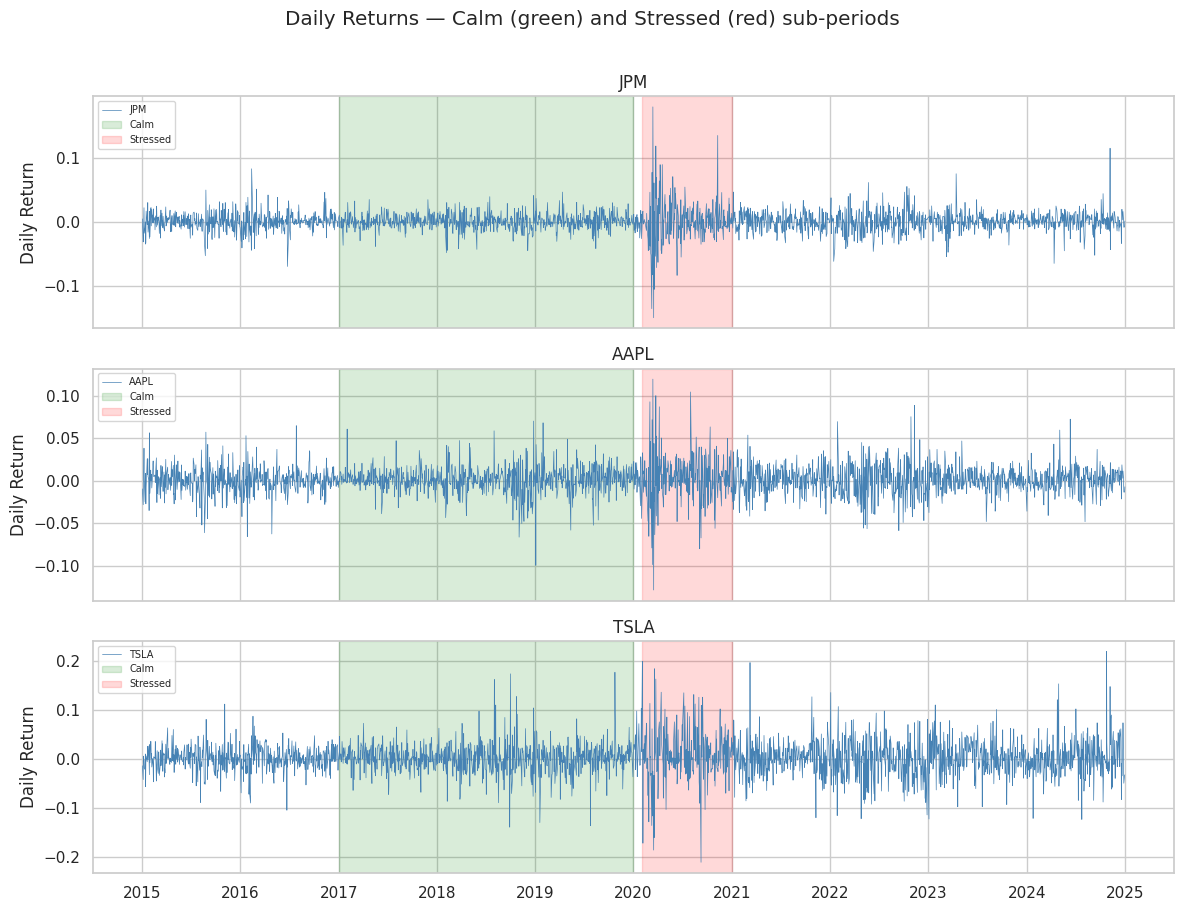

In [11]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

fig, axes = plt.subplots(len(PERMNOS), 1, figsize=(12, 9), sharex=True)
for ax, (ticker, _) in zip(axes, PERMNOS.items()):
    sub = df[df['ticker'] == ticker]
    ax.plot(sub['date'], sub['ret'], lw=0.5, color='steelblue', label=ticker)
    # Shade sub-periods
    ax.axvspan(CALM_START, CALM_END, alpha=0.15, color='green', label='Calm')
    ax.axvspan(STRESSED_START, STRESSED_END, alpha=0.15, color='red', label='Stressed')
    ax.set_ylabel('Daily Return')
    ax.set_title(ticker)
    ax.legend(loc='upper left', fontsize=7)

axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
fig.suptitle('Daily Returns — Calm (green) and Stressed (red) sub-periods', y=1.01)
plt.tight_layout()
os.makedirs(os.path.join(PROJECT_ROOT, 'outputs', 'figures'), exist_ok=True)
fig.savefig(os.path.join(PROJECT_ROOT, 'outputs', 'figures', '01_return_series.png'), dpi=150, bbox_inches='tight')
plt.show()

---

## Section 02 — Descriptive Analysis and Distribution Fitting


## 1. Summary statistics

In [12]:
from scipy.stats import jarque_bera, skew, kurtosis

rows = []
for ticker in TICKERS:
    for period in ['full', 'calm', 'stressed']:
        if period == 'full':
            sub = df[df['ticker'] == ticker]['ret'].dropna()
        else:
            sub = df[(df['ticker'] == ticker) & (df['period'] == period)]['ret'].dropna()
        if len(sub) == 0:
            continue
        jb_stat, jb_p = jarque_bera(sub)
        rows.append({
            'Ticker': ticker,
            'Period': period,
            'N': len(sub),
            'Mean (%)': round(sub.mean() * 100, 4),
            'SD (%)': round(sub.std(ddof=1) * 100, 4),
            'Min (%)': round(sub.min() * 100, 2),
            'Max (%)': round(sub.max() * 100, 2),
            'Skewness': round(skew(sub), 3),
            'Excess Kurtosis': round(kurtosis(sub, fisher=True), 3),
            'JB stat': round(jb_stat, 2),
            'JB p-value': round(jb_p, 4),
        })

stats_table = pd.DataFrame(rows)
stats_table.to_csv(os.path.join(TAB_DIR, '02_summary_stats.csv'), index=False)
stats_table

,Ticker,Period,N,Mean (%),SD (%),Min (%),Max (%),Skewness,Excess Kurtosis,JB stat,JB p-value
0,JPM,full,2516,0.0792,1.7237,-14.96,18.01,0.380,13.909,20340.36,0.0
1,JPM,calm,754,0.0810,1.2086,-4.80,4.69,-0.095,1.852,108.88,0.0
2,JPM,stressed,232,0.0578,3.5558,-14.96,18.01,0.363,5.408,287.80,0.0
3,AAPL,full,2516,0.1084,1.7927,-12.86,11.98,-0.002,5.302,2946.95,0.0
4,AAPL,calm,754,0.1416,1.5534,-9.96,7.04,-0.347,4.815,743.47,0.0
5,AAPL,stressed,232,0.2820,3.0240,-12.86,11.98,-0.044,3.416,112.87,0.0
6,TSLA,full,2516,0.1959,3.6003,-21.06,21.92,0.276,4.386,2048.23,0.0
7,TSLA,calm,754,0.1357,3.0632,-13.90,17.67,0.419,5.456,957.37,0.0
8,TSLA,stressed,232,0.8977,5.7636,-21.06,19.89,-0.166,2.092,43.37,0.0


**Interpretation:**  
- All tickers show excess kurtosis > 3 (Normal has excess kurtosis = 0), consistent with heavy tails.  
- Jarque–Bera tests reject normality for all tickers and sub-periods (p < 0.05).  
- Skewness is negative for most, indicating the left tail (large losses) is heavier than implied by symmetry.  
- This motivates fitting a Student-t distribution as a calibrated heavy-tailed DGP.

## 2. Histograms and Q-Q plots vs. Normal

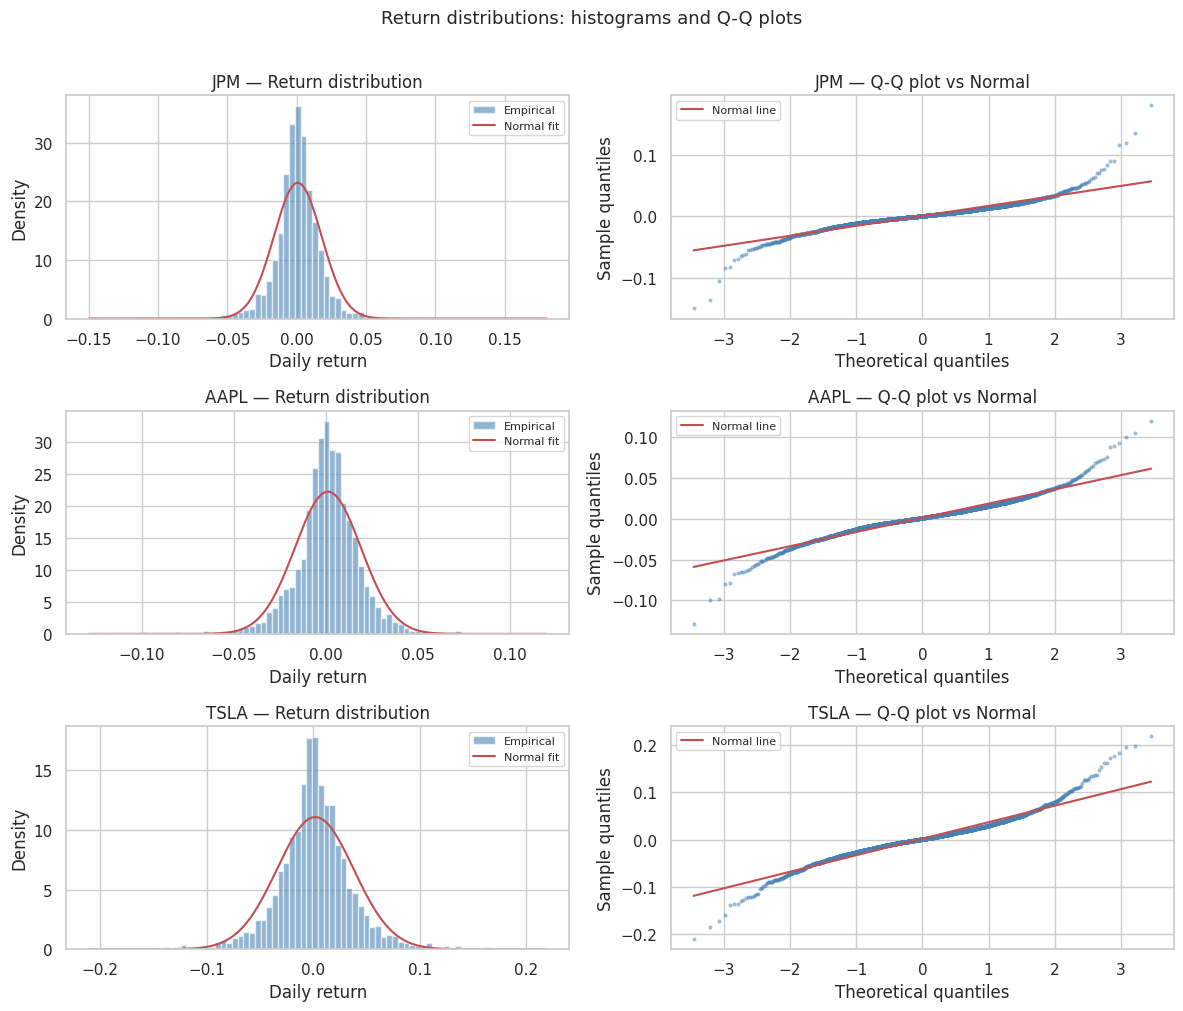

Heavy tails show up as deviations from the red line in the Q-Q plot corners.


In [13]:
fig, axes = plt.subplots(len(TICKERS), 2, figsize=(12, 10))

for i, ticker in enumerate(TICKERS):
    ret = df[df['ticker'] == ticker]['ret'].dropna().values
    loss = -ret

    # Histogram with Normal overlay
    ax = axes[i, 0]
    ax.hist(ret, bins=80, density=True, color='steelblue', alpha=0.6, label='Empirical')
    x = np.linspace(ret.min(), ret.max(), 300)
    ax.plot(x, stats.norm.pdf(x, ret.mean(), ret.std(ddof=1)), 'r-', lw=1.5, label='Normal fit')
    ax.set_title(f'{ticker} — Return distribution')
    ax.set_xlabel('Daily return')
    ax.set_ylabel('Density')
    ax.legend(fontsize=8)

    # Q-Q plot vs Normal
    ax = axes[i, 1]
    (osm, osr), (slope, intercept, r) = stats.probplot(ret, dist='norm')
    ax.scatter(osm, osr, s=4, alpha=0.4, color='steelblue')
    ax.plot([osm[0], osm[-1]], [slope * osm[0] + intercept, slope * osm[-1] + intercept],
            'r-', lw=1.5, label='Normal line')
    ax.set_title(f'{ticker} — Q-Q plot vs Normal')
    ax.set_xlabel('Theoretical quantiles')
    ax.set_ylabel('Sample quantiles')
    ax.legend(fontsize=8)

plt.suptitle('Return distributions: histograms and Q-Q plots', y=1.01, fontsize=13)
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, '02_hist_qq.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Heavy tails show up as deviations from the red line in the Q-Q plot corners.')

## 3. Student-t MLE fit

We fit a three-parameter Student-t (location, scale, degrees of freedom) by MLE using `scipy.stats.t.fit`.  
The fitted parameters become the calibrated DGP for the Monte Carlo study in Notebook 04.

In [14]:
t_params_all = {}

fit_rows = []
for ticker in TICKERS:
    for period in ['full', 'calm', 'stressed']:
        if period == 'full':
            losses = df[df['ticker'] == ticker]['loss'].dropna().values
        else:
            losses = df[(df['ticker'] == ticker) & (df['period'] == period)]['loss'].dropna().values
        if len(losses) < 30:
            continue
        df_t, loc, scale = fit_student_t(losses)
        t_params_all[f'{ticker}_{period}'] = {'df': df_t, 'loc': loc, 'scale': scale, 'n': len(losses)}
        fit_rows.append({
            'Ticker': ticker, 'Period': period, 'N': len(losses),
            'df (nu)': round(df_t, 3), 'loc': round(loc, 6), 'scale': round(scale, 6)
        })

fit_table = pd.DataFrame(fit_rows)
fit_table.to_csv(os.path.join(TAB_DIR, '02_t_fit_params.csv'), index=False)
print(fit_table.to_string(index=False))

# Save fitted parameters for later notebooks
with open(os.path.join(MDL_DIR, 't_params.json'), 'w') as f:
    json.dump(t_params_all, f, indent=2)
print('\nFitted parameters saved to models/t_params.json')

Ticker   Period    N  df (nu)       loc    scale
   JPM     full 2516    2.976 -0.000792 0.010374
   JPM     calm  754    4.115 -0.000810 0.008985
   JPM stressed  232    2.680 -0.000578 0.020849
  AAPL     full 2516    3.331 -0.001084 0.011953
  AAPL     calm  754    2.963 -0.001416 0.009833
  AAPL stressed  232    2.996 -0.002820 0.019296
  TSLA     full 2516    3.218 -0.001959 0.023739
  TSLA     calm  754    3.409 -0.001357 0.020371
  TSLA stressed  232    3.356 -0.008977 0.039632

Fitted parameters saved to models/t_params.json


**Interpretation of degrees of freedom (ν):**  
- ν < 5: very heavy tails (common for individual equities).  
- ν → ∞: Student-t approaches Normal.  
- Low ν in stressed periods confirms heavier tails under market stress.

## 4. Density overlays: Empirical vs. Normal vs. Student-t

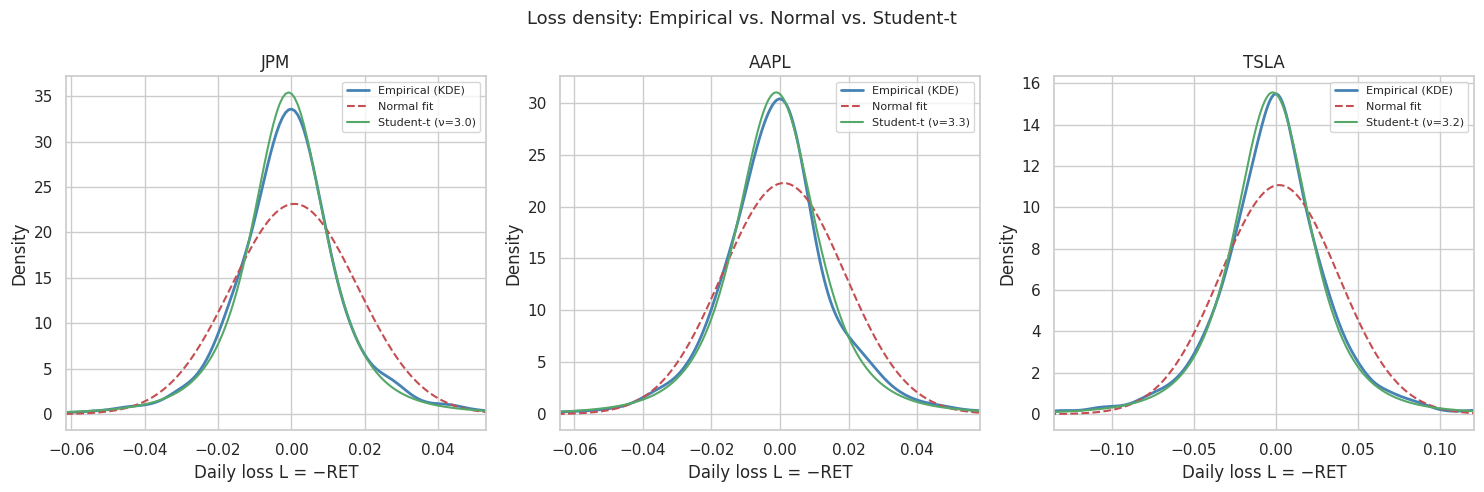

In [15]:
fig, axes = plt.subplots(1, len(TICKERS), figsize=(15, 5))

for ax, ticker in zip(axes, TICKERS):
    losses = df[df['ticker'] == ticker]['loss'].dropna().values
    p = t_params_all[f'{ticker}_full']

    # Kernel density of empirical losses
    kde = stats.gaussian_kde(losses)
    x = np.linspace(losses.min(), losses.max(), 400)

    ax.plot(x, kde(x), 'steelblue', lw=2, label='Empirical (KDE)')
    ax.plot(x, stats.norm.pdf(x, -losses.mean(), losses.std(ddof=1)),
            'r--', lw=1.5, label='Normal fit')
    ax.plot(x, stats.t.pdf(x, df=p['df'], loc=p['loc'], scale=p['scale']),
            'g-', lw=1.5, label=f'Student-t (ν={p["df"]:.1f})')

    ax.set_xlim(np.percentile(losses, 0.5), np.percentile(losses, 99.5))
    ax.set_title(ticker)
    ax.set_xlabel('Daily loss L = −RET')
    ax.set_ylabel('Density')
    ax.legend(fontsize=8)

plt.suptitle('Loss density: Empirical vs. Normal vs. Student-t', fontsize=13)
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, '02_density_overlay.png'), dpi=150, bbox_inches='tight')
plt.show()

## 5. Chebyshev inequality comparison

**Course method (Wk 4):** Chebyshev's inequality gives a distribution-free upper bound on the probability of a deviation from the mean:

$$P(|R - \mu| \geq k\sigma) \leq \frac{1}{k^2}$$

We compare this bound against:
- The **Normal prediction**: $2\Phi(-k)$
- The **observed empirical frequency** from our data

**Why Chebyshev, not Markov?**  
Markov's inequality requires a non-negative random variable. The daily return R (and loss L = −R) can be negative, violating this requirement. Chebyshev applies to any random variable with finite variance and works with deviations from the mean in both directions.

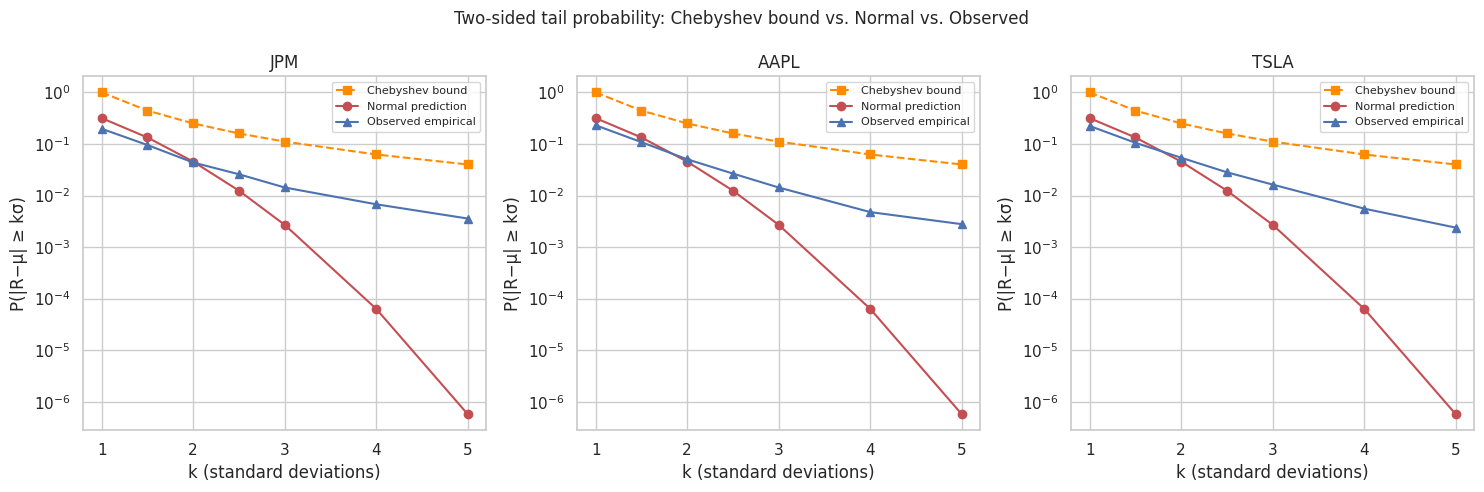

Chebyshev comparison saved.


In [16]:
k_values = np.array([1.0, 1.5, 2.0, 2.5, 3.0, 4.0, 5.0])

cheb_rows = []

fig, axes = plt.subplots(1, len(TICKERS), figsize=(15, 5))

for ax, ticker in zip(axes, TICKERS):
    ret = df[df['ticker'] == ticker]['ret'].dropna().values
    mu, sigma = ret.mean(), ret.std(ddof=1)

    chebyshev_bound   = 1.0 / k_values**2
    normal_prediction = 2 * stats.norm.sf(k_values)
    observed = np.array([
        np.mean(np.abs(ret - mu) >= k * sigma) for k in k_values
    ])

    ax.plot(k_values, chebyshev_bound, 's--', color='darkorange', label='Chebyshev bound')
    ax.plot(k_values, normal_prediction, 'r-o', label='Normal prediction')
    ax.plot(k_values, observed, 'b-^', label='Observed empirical')
    ax.set_yscale('log')
    ax.set_xlabel('k (standard deviations)')
    ax.set_ylabel('P(|R−μ| ≥ kσ)')
    ax.set_title(ticker)
    ax.legend(fontsize=8)

    for k, cb, np_, ob in zip(k_values, chebyshev_bound, normal_prediction, observed):
        cheb_rows.append({
            'Ticker': ticker, 'k': k,
            'Chebyshev_bound': round(cb, 6),
            'Normal_prediction': round(np_, 6),
            'Observed': round(ob, 6),
        })

plt.suptitle('Two-sided tail probability: Chebyshev bound vs. Normal vs. Observed', fontsize=12)
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, '02_chebyshev.png'), dpi=150, bbox_inches='tight')
plt.show()

cheb_table = pd.DataFrame(cheb_rows)
cheb_table.to_csv(os.path.join(TAB_DIR, '02_chebyshev_comparison.csv'), index=False)
print('Chebyshev comparison saved.')

**Interpretation:**  
- The **Chebyshev bound** is always valid but very conservative — it always lies above the observed probability.  
- The **Normal prediction** underestimates the actual tail probability at k ≥ 2 for all equities, because real returns are heavier-tailed than Normal.  
- The **observed empirical frequency** sits between Chebyshev (conservative) and Normal (optimistic) at moderate k, but exceeds the Normal prediction significantly at k ≥ 3.  
- This shows that using a Normal VaR/CVaR model at the 99% level (≈ k ≈ 2.33σ threshold) will materially understate risk for heavy-tailed equity returns — the central motivation for comparing estimators.

---

## Section 03 — VaR and CVaR Estimator Implementation


## 1. Sanity check on synthetic data

We generate data from a known Normal(0, 1) distribution and verify that all estimators recover the true VaR and CVaR analytically.  
For N(0,1): VaR_{0.99} = Φ⁻¹(0.99) ≈ 2.326, CVaR_{0.99} = φ(Φ⁻¹(0.99)) / (1−0.99) ≈ 2.665.

In [17]:
rng = np.random.default_rng(42)
N_SANITY = 100_000
synth = rng.standard_normal(N_SANITY)  # losses ~ N(0,1)

alpha = 0.99
true_var_norm  = stats.norm.ppf(alpha)
true_cvar_norm = stats.norm.pdf(stats.norm.ppf(alpha)) / (1 - alpha)

print(f'True VaR_{{0.99}}  (Normal): {true_var_norm:.6f}')
print(f'True CVaR_{{0.99}} (Normal): {true_cvar_norm:.6f}')
print()
print(f'Historical VaR:            {historical_var(synth, alpha):.6f}')
print(f'Historical CVaR:           {historical_cvar(synth, alpha):.6f}')
print(f'Parametric Normal VaR:     {parametric_normal_var(synth, alpha):.6f}')
print(f'Parametric Normal CVaR:    {parametric_normal_cvar(synth, alpha):.6f}')

# Student-t fit on Normal data should give high df (approaching Normal)
df_t, loc, scale = fit_student_t(synth)
print(f'\nStudent-t MLE on Normal data: df={df_t:.1f}, loc={loc:.4f}, scale={scale:.4f}')
print(f'Parametric Student-t VaR:  {parametric_t_var(synth, alpha, (df_t, loc, scale)):.6f}')
print(f'Parametric Student-t CVaR: {parametric_t_cvar(synth, alpha, (df_t, loc, scale)):.6f}')

True VaR_{0.99}  (Normal): 2.326348
True CVaR_{0.99} (Normal): 2.665214

Historical VaR:            2.343238
Historical CVaR:           2.679605
Parametric Normal VaR:     2.330742
Parametric Normal CVaR:    2.670865

Student-t MLE on Normal data: df=267.6, loc=-0.0042, scale=0.9999
Parametric Student-t VaR:  2.336003
Parametric Student-t CVaR: 2.681943


**Expected result:** All estimators should recover values close to 2.326 (VaR) and 2.665 (CVaR) for N=100,000 draws. Small discrepancies are sampling error; they should vanish as N → ∞. Student-t degrees of freedom should be large (≫30), confirming it converges to Normal on Normal data.

## 2. Estimators on real data

In [18]:
records = []
for ticker in TICKERS:
    for period in ['full', 'calm', 'stressed']:
        if period == 'full':
            losses = df[df['ticker'] == ticker]['loss'].dropna().values
        else:
            losses = df[(df['ticker'] == ticker) & (df['period'] == period)]['loss'].dropna().values
        if len(losses) < 30:
            continue
        key = f'{ticker}_{period}'
        p = t_params_all.get(key)
        t_params = (p['df'], p['loc'], p['scale']) if p else None

        for alpha in ALPHAS:
            a_str = f'{int(alpha*100)}%'
            records.append({
                'Ticker': ticker, 'Period': period, 'Alpha': a_str, 'N': len(losses),
                'Hist VaR':   round(historical_var(losses, alpha) * 100, 4),
                'Hist CVaR':  round(historical_cvar(losses, alpha) * 100, 4),
                'Norm VaR':   round(parametric_normal_var(losses, alpha) * 100, 4),
                'Norm CVaR':  round(parametric_normal_cvar(losses, alpha) * 100, 4),
                't VaR':      round(parametric_t_var(losses, alpha, t_params) * 100, 4),
                't CVaR':     round(parametric_t_cvar(losses, alpha, t_params) * 100, 4),
            })

est_table = pd.DataFrame(records)
est_table.to_csv(os.path.join(TAB_DIR, '03_estimator_results.csv'), index=False)
est_table

,Ticker,Period,Alpha,N,Hist VaR,Hist CVaR,Norm VaR,Norm CVaR,t VaR,t CVaR
0,JPM,full,95%,2516,2.5338,3.8618,2.7561,3.4764,2.3702,3.9666
1,JPM,full,99%,2516,4.4434,6.4237,3.9308,4.5149,4.6621,7.2601
2,JPM,calm,95%,754,1.8644,2.7258,1.9070,2.4120,1.8193,2.7546
3,JPM,calm,99%,754,3.3099,4.2158,2.7306,3.1401,3.2346,4.5036
4,JPM,stressed,95%,232,4.7966,7.9073,5.7910,7.2768,5.0974,8.8709
5,JPM,stressed,99%,232,9.8503,13.0124,8.2142,9.4192,10.3767,16.9609
6,AAPL,full,95%,2516,2.6985,4.0717,2.8403,3.5894,2.5942,4.1722
7,AAPL,full,99%,2516,4.7975,6.4445,4.0620,4.6694,4.9105,7.3076
8,AAPL,calm,95%,754,2.3474,3.6553,2.4134,3.0625,2.1843,3.7071
9,AAPL,calm,99%,754,4.5038,5.8388,3.4720,3.9984,4.3684,6.8535


## 3. Visualisation: VaR comparison by method, ticker, period

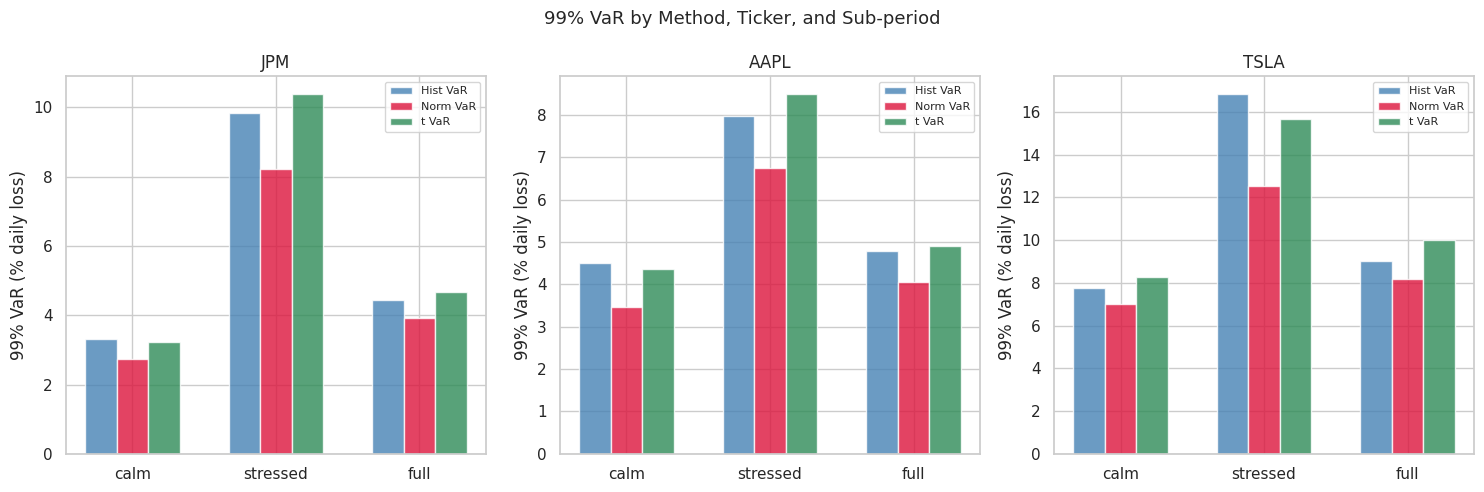

In [19]:
# Focus on 99% VaR for the bar chart
sub99 = est_table[est_table['Alpha'] == '99%'].copy()

fig, axes = plt.subplots(1, len(TICKERS), figsize=(15, 5), sharey=False)
methods = ['Hist VaR', 'Norm VaR', 't VaR']
colors  = ['steelblue', 'crimson', 'seagreen']
x = np.arange(3)  # calm, stressed, full
periods = ['calm', 'stressed', 'full']
width = 0.22

for ax, ticker in zip(axes, TICKERS):
    sub = sub99[sub99['Ticker'] == ticker]
    for i, (method, color) in enumerate(zip(methods, colors)):
        vals = [sub[sub['Period'] == p][method].values[0] if len(sub[sub['Period'] == p]) > 0 else 0
                for p in periods]
        ax.bar(x + i * width - width, vals, width, label=method, color=color, alpha=0.8)
    ax.set_xticks(x)
    ax.set_xticklabels(periods)
    ax.set_title(ticker)
    ax.set_ylabel('99% VaR (% daily loss)')
    ax.legend(fontsize=8)

plt.suptitle('99% VaR by Method, Ticker, and Sub-period', fontsize=13)
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, '03_var_comparison.png'), dpi=150, bbox_inches='tight')
plt.show()

**Interpretation:**  
- The **Normal estimator** consistently produces lower VaR values than historical or Student-t, especially in stressed periods — underestimating tail risk.  
- The **Student-t estimator** generally gives higher VaR, correctly accounting for heavy tails.  
- **Stressed** VaR estimates are substantially higher than calm estimates, validating that the sub-period split captures meaningful regime differences.  
- **TSLA** shows the highest VaR across all methods, consistent with its high-volatility profile.

## 4. VaR and CVaR on the loss distribution plot

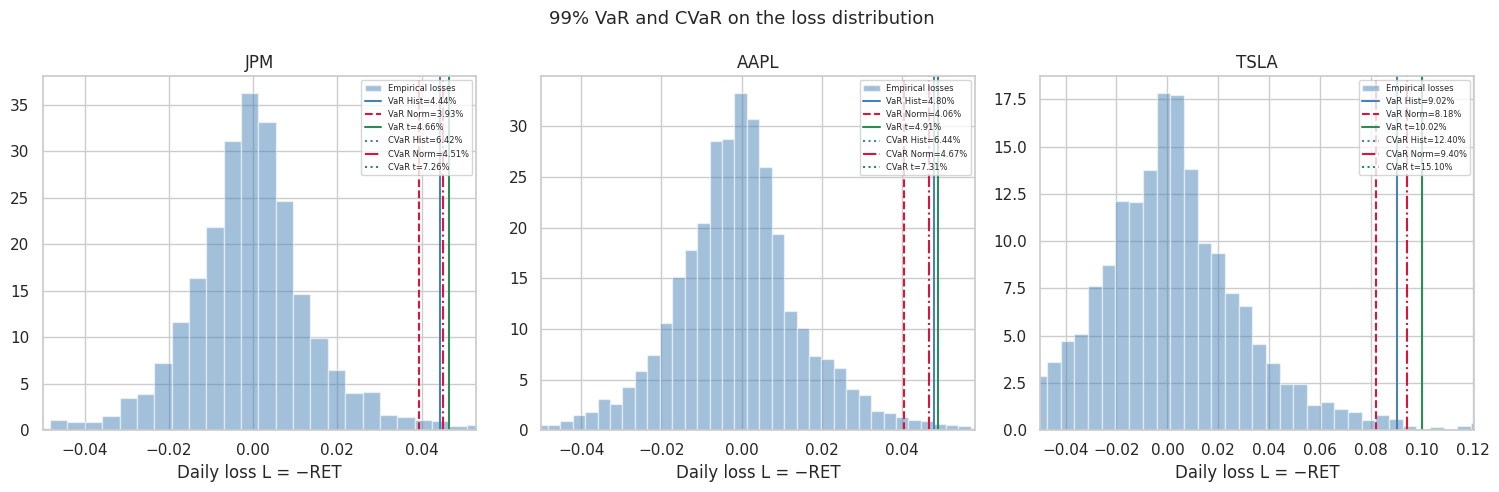

In [20]:
fig, axes = plt.subplots(1, len(TICKERS), figsize=(15, 5))
alpha = 0.99

for ax, ticker in zip(axes, TICKERS):
    losses = df[df['ticker'] == ticker]['loss'].dropna().values
    p = t_params_all[f'{ticker}_full']
    t_params = (p['df'], p['loc'], p['scale'])

    ax.hist(losses, bins=80, density=True, color='steelblue', alpha=0.5, label='Empirical losses')

    var_h = historical_var(losses, alpha)
    var_n = parametric_normal_var(losses, alpha)
    var_t = parametric_t_var(losses, alpha, t_params)
    cvar_h = historical_cvar(losses, alpha)
    cvar_n = parametric_normal_cvar(losses, alpha)
    cvar_t = parametric_t_cvar(losses, alpha, t_params)

    ymax = ax.get_ylim()[1]
    for val, label, color, ls in [
        (var_h,  'VaR Hist',  'steelblue', '-'),
        (var_n,  'VaR Norm',  'crimson',   '--'),
        (var_t,  'VaR t',     'seagreen',  '-'),
        (cvar_h, 'CVaR Hist', 'steelblue', ':'),
        (cvar_n, 'CVaR Norm', 'crimson',   '-.'),
        (cvar_t, 'CVaR t',    'seagreen',  ':'),
    ]:
        ax.axvline(val, color=color, ls=ls, lw=1.5, label=f'{label}={val*100:.2f}%')

    ax.set_xlim(-0.05, np.percentile(losses, 99.5))
    ax.set_title(ticker)
    ax.set_xlabel('Daily loss L = −RET')
    ax.legend(fontsize=6, loc='upper right')

plt.suptitle('99% VaR and CVaR on the loss distribution', fontsize=13)
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, '03_var_cvar_on_dist.png'), dpi=150, bbox_inches='tight')
plt.show()

---

## Section 04 — Monte Carlo Finite-Sample Study


In [21]:
with open(os.path.join(MDL_DIR, 't_params.json')) as f:
    t_params_all = json.load(f)

# We use the full-sample fitted parameters as the calibrated DGP
for ticker in TICKERS:
    p = t_params_all[f'{ticker}_full']
    tv99 = true_t_var(p['df'], p['loc'], p['scale'], 0.99)
    tc99 = true_t_cvar(p['df'], p['loc'], p['scale'], 0.99)
    print(f"{ticker}: ν={p['df']:.2f}, true VaR_99={tv99*100:.3f}%, true CVaR_99={tc99*100:.3f}%")

JPM: ν=2.98, true VaR_99=4.662%, true CVaR_99=7.260%
AAPL: ν=3.33, true VaR_99=4.910%, true CVaR_99=7.308%
TSLA: ν=3.22, true VaR_99=10.020%, true CVaR_99=15.100%


## 1. Run Monte Carlo (all tickers, full-sample DGP)

This cell may take 1–3 minutes for 1,000 replications across all settings. Results are cached to disk.

In [22]:
all_mc = {}
mc_cache_path = os.path.join(TAB_DIR, '04_mc_results.parquet')

if os.path.exists(mc_cache_path):
    mc_all_df = pd.read_parquet(mc_cache_path)
    print(f'Loaded cached MC results from {mc_cache_path}')
else:
    dfs = []
    for ticker in TICKERS:
        p = t_params_all[f'{ticker}_full']
        print(f'Running MC for {ticker} (df={p["df"]:.2f})...')
        mc_df = run_monte_carlo(
            df=p['df'], loc=p['loc'], scale=p['scale'],
            sample_sizes=SAMPLE_SIZES, n_reps=N_REPS,
            alphas=(0.95, 0.99), seed=SEED,
        )
        mc_df['ticker'] = ticker
        dfs.append(mc_df)
        print(f'  Done — {len(mc_df)} rows.')
    mc_all_df = pd.concat(dfs, ignore_index=True)
    mc_all_df.to_parquet(mc_cache_path, index=False)
    print(f'\nSaved MC results to {mc_cache_path}')

mc_all_df.head()

Loaded cached MC results from /content/drive/MyDrive/DS603_Project/outputs/tables/04_mc_results.parquet


,alpha,n,estimator,measure,true_value,mean_estimate,bias,sd,rmse,ticker
0,0.95,60,hist,var,0.023702,0.022605,-0.001098,0.006007,0.006104,JPM
1,0.95,60,norm,var,0.023702,0.027325,0.003623,0.012401,0.012914,JPM
2,0.95,60,t,var,0.023702,0.023649,-0.000053,0.004362,0.004360,JPM
3,0.95,60,hist,cvar,0.039666,0.038243,-0.001423,0.015509,0.015566,JPM
4,0.95,60,norm,cvar,0.039666,0.034469,-0.005198,0.015614,0.016449,JPM


## 2. Summary tables: Bias, SD, RMSE

In [23]:
# Focus on 99% VaR — the primary confidence level
mc_99_var = mc_all_df[(mc_all_df['alpha'] == 0.99) & (mc_all_df['measure'] == 'var')].copy()

pivot_bias = mc_99_var.pivot_table(index=['ticker', 'estimator'], columns='n', values='bias')
pivot_rmse = mc_99_var.pivot_table(index=['ticker', 'estimator'], columns='n', values='rmse')

print('=== 99% VaR Bias (×100 = percentage points) ===')
print((pivot_bias * 100).round(4).to_string())

print('\n=== 99% VaR RMSE (×100 = percentage points) ===')
print((pivot_rmse * 100).round(4).to_string())

# Save full table
mc_99_var.to_csv(os.path.join(TAB_DIR, '04_mc_99var_summary.csv'), index=False)

=== 99% VaR Bias (×100 = percentage points) ===
n                   60      250     1000
ticker estimator                        
AAPL   hist      -0.6047 -0.1876 -0.0700
       norm      -0.8378 -0.6872 -0.6397
       t         -0.1557 -0.0286 -0.0089
JPM    hist      -0.5487 -0.1801 -0.0442
       norm      -0.8002 -0.6405 -0.5461
       t         -0.1142 -0.0172  0.0012
TSLA   hist      -1.2292 -0.4401 -0.1207
       norm      -1.7219 -1.3907 -1.3046
       t         -0.2919 -0.0527 -0.0156

=== 99% VaR RMSE (×100 = percentage points) ===
n                   60      250     1000
ticker estimator                        
AAPL   hist       1.7229  1.0296  0.5125
       norm       1.2496  0.9727  0.8593
       t          1.2684  0.6251  0.3063
JPM    hist       1.8864  1.0412  0.5414
       norm       1.4719  1.2526  1.3414
       t          1.3913  0.6372  0.3072
TSLA   hist       3.7407  2.1035  1.0811
       norm       2.7299  2.1503  1.7791
       t          2.7561  1.2953  0.6267


## 3. Convergence curves: Bias and RMSE vs. sample size

**LLN/CLT connection (Wk 10):** As n → ∞, each estimator's bias → 0 and RMSE → 0 (Law of Large Numbers). The rate of RMSE decrease ∝ 1/√n reflects the Central Limit Theorem.

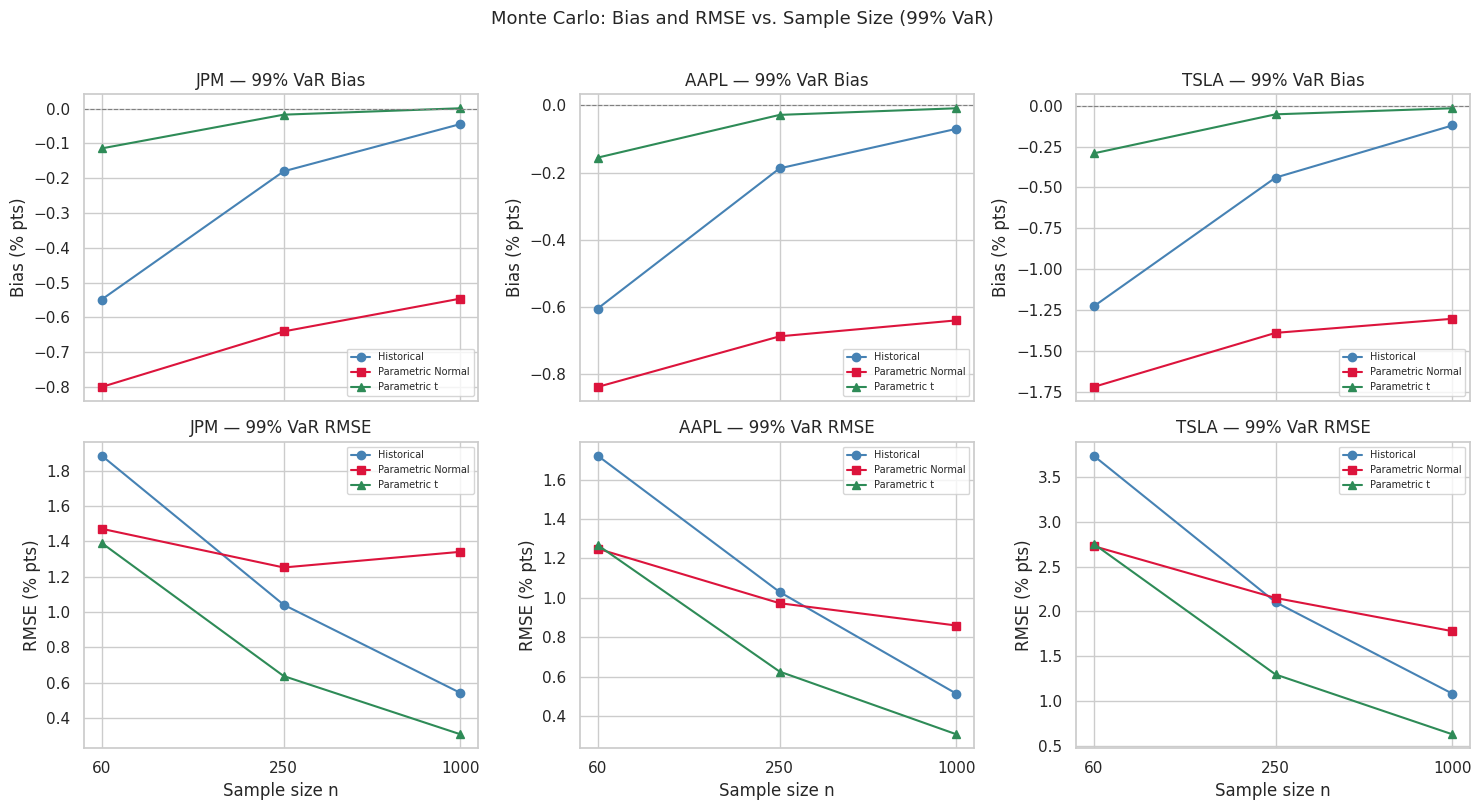

In [24]:
EST_LABELS = {'hist': 'Historical', 'norm': 'Parametric Normal', 't': 'Parametric t'}
EST_COLORS = {'hist': 'steelblue', 'norm': 'crimson', 't': 'seagreen'}
EST_MARKERS = {'hist': 'o', 'norm': 's', 't': '^'}

fig, axes = plt.subplots(2, len(TICKERS), figsize=(15, 8), sharex=True)

for col, ticker in enumerate(TICKERS):
    for alpha_val, alpha_str, measure in [(0.99, '99%', 'var')]:
        mc_sub = mc_all_df[
            (mc_all_df['ticker'] == ticker) &
            (mc_all_df['alpha'] == alpha_val) &
            (mc_all_df['measure'] == measure)
        ]

        ax_bias = axes[0, col]
        ax_rmse = axes[1, col]

        for est in ['hist', 'norm', 't']:
            sub = mc_sub[mc_sub['estimator'] == est].sort_values('n')
            ax_bias.plot(sub['n'], sub['bias'] * 100, color=EST_COLORS[est],
                        marker=EST_MARKERS[est], label=EST_LABELS[est], lw=1.5)
            ax_rmse.plot(sub['n'], sub['rmse'] * 100, color=EST_COLORS[est],
                        marker=EST_MARKERS[est], label=EST_LABELS[est], lw=1.5)

        ax_bias.axhline(0, color='grey', lw=0.8, ls='--')
        ax_bias.set_title(f'{ticker} — {alpha_str} VaR Bias')
        ax_bias.set_ylabel('Bias (% pts)')
        ax_bias.legend(fontsize=7)
        ax_bias.set_xscale('log')

        ax_rmse.set_title(f'{ticker} — {alpha_str} VaR RMSE')
        ax_rmse.set_ylabel('RMSE (% pts)')
        ax_rmse.set_xlabel('Sample size n')
        ax_rmse.legend(fontsize=7)
        ax_rmse.set_xscale('log')
        ax_rmse.set_xticks(SAMPLE_SIZES)
        ax_rmse.set_xticklabels([str(s) for s in SAMPLE_SIZES])

plt.suptitle('Monte Carlo: Bias and RMSE vs. Sample Size (99% VaR)', fontsize=13, y=1.01)
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, '04_mc_convergence.png'), dpi=150, bbox_inches='tight')
plt.show()

## 4. CVaR convergence curves

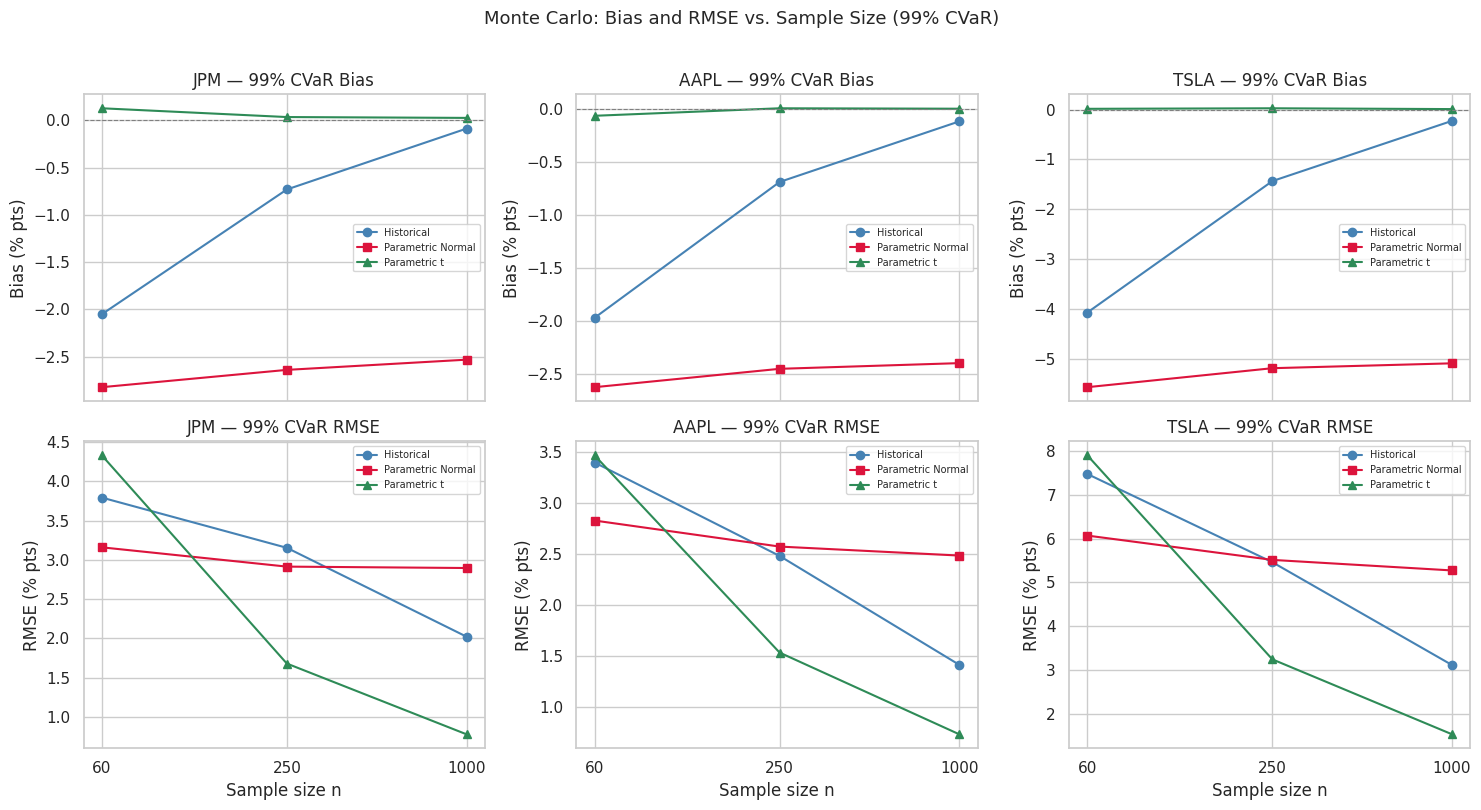

In [25]:
fig, axes = plt.subplots(2, len(TICKERS), figsize=(15, 8), sharex=True)

for col, ticker in enumerate(TICKERS):
    mc_sub = mc_all_df[
        (mc_all_df['ticker'] == ticker) &
        (mc_all_df['alpha'] == 0.99) &
        (mc_all_df['measure'] == 'cvar')
    ]

    ax_bias = axes[0, col]
    ax_rmse = axes[1, col]

    for est in ['hist', 'norm', 't']:
        sub = mc_sub[mc_sub['estimator'] == est].sort_values('n')
        ax_bias.plot(sub['n'], sub['bias'] * 100, color=EST_COLORS[est],
                    marker=EST_MARKERS[est], label=EST_LABELS[est], lw=1.5)
        ax_rmse.plot(sub['n'], sub['rmse'] * 100, color=EST_COLORS[est],
                    marker=EST_MARKERS[est], label=EST_LABELS[est], lw=1.5)

    ax_bias.axhline(0, color='grey', lw=0.8, ls='--')
    ax_bias.set_title(f'{ticker} — 99% CVaR Bias')
    ax_bias.set_ylabel('Bias (% pts)')
    ax_bias.legend(fontsize=7)
    ax_bias.set_xscale('log')

    ax_rmse.set_title(f'{ticker} — 99% CVaR RMSE')
    ax_rmse.set_ylabel('RMSE (% pts)')
    ax_rmse.set_xlabel('Sample size n')
    ax_rmse.legend(fontsize=7)
    ax_rmse.set_xscale('log')
    ax_rmse.set_xticks(SAMPLE_SIZES)
    ax_rmse.set_xticklabels([str(s) for s in SAMPLE_SIZES])

plt.suptitle('Monte Carlo: Bias and RMSE vs. Sample Size (99% CVaR)', fontsize=13, y=1.01)
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, '04_mc_cvar_convergence.png'), dpi=150, bbox_inches='tight')
plt.show()

## 5. How badly does the Normal estimator understate risk under heavy tails?

In [26]:
print('=== Normal estimator bias relative to true VaR (at n=1000, alpha=0.99) ===')
print('Positive bias = overestimates, Negative bias = UNDERSTATES risk\n')

rows = []
for ticker in TICKERS:
    p = t_params_all[f'{ticker}_full']
    true_var  = true_t_var(p['df'], p['loc'], p['scale'], 0.99)
    true_cvar = true_t_cvar(p['df'], p['loc'], p['scale'], 0.99)

    mc_sub = mc_all_df[
        (mc_all_df['ticker'] == ticker) &
        (mc_all_df['alpha'] == 0.99) &
        (mc_all_df['n'] == 1000)
    ]

    for measure, true_val in [('var', true_var), ('cvar', true_cvar)]:
        for est in ['hist', 'norm', 't']:
            row = mc_sub[(mc_sub['measure'] == measure) & (mc_sub['estimator'] == est)]
            if len(row) == 0:
                continue
            bias = row['bias'].values[0]
            pct_bias = bias / abs(true_val) * 100
            rows.append({
                'Ticker': ticker,
                'Measure': measure.upper(),
                'Estimator': EST_LABELS[est],
                'True value (%)': round(true_val * 100, 4),
                'Bias (pp)': round(bias * 100, 4),
                'Bias (% of true)': round(pct_bias, 2),
            })

understat_df = pd.DataFrame(rows)
understat_df.to_csv(os.path.join(TAB_DIR, '04_normal_understatement.csv'), index=False)
print(understat_df.to_string(index=False))

=== Normal estimator bias relative to true VaR (at n=1000, alpha=0.99) ===
Positive bias = overestimates, Negative bias = UNDERSTATES risk

Ticker Measure         Estimator  True value (%)  Bias (pp)  Bias (% of true)
   JPM     VAR        Historical          4.6621    -0.0442             -0.95
   JPM     VAR Parametric Normal          4.6621    -0.5461            -11.71
   JPM     VAR      Parametric t          4.6621     0.0012              0.03
   JPM    CVAR        Historical          7.2601    -0.0870             -1.20
   JPM    CVAR Parametric Normal          7.2601    -2.5330            -34.89
   JPM    CVAR      Parametric t          7.2601     0.0262              0.36
  AAPL     VAR        Historical          4.9105    -0.0700             -1.43
  AAPL     VAR Parametric Normal          4.9105    -0.6397            -13.03
  AAPL     VAR      Parametric t          4.9105    -0.0089             -0.18
  AAPL    CVAR        Historical          7.3076    -0.1178             -1.61
  

## 6. Interpretation

**Key findings:**

1. **All estimators converge** as n increases (bias → 0, RMSE → 0), consistent with LLN/CLT. RMSE decreases approximately as 1/√n.

2. **Normal estimator bias at the 99% level:**  
   Under heavy-tailed t-distributed data, the Normal estimator systematically **understates** VaR and CVaR (negative bias). This understatement is more severe:  
   - At higher confidence levels (99% vs 95%), because tail divergence grows with k.  
   - For TSLA (lower ν, heavier tails) than for JPM or AAPL.  
   - For CVaR than for VaR, because CVaR measures the average of the full tail beyond VaR.

3. **Historical estimator** is unbiased asymptotically but has high RMSE at small n (n=60), because estimating extreme quantiles from 60 observations is inherently noisy. At n=1000 it performs well.

4. **Student-t estimator** is unbiased by construction when the DGP is t, and has lower RMSE than historical at small n. It is the correct choice when tail heaviness has been confirmed.

5. **Decision-maker takeaway:** Use the Student-t estimator for 99% VaR/CVaR on individual equities — it is well-calibrated under heavy tails and more efficient than historical simulation at short horizons. The Normal estimator should be avoided for tail risk at 99%; it can understate risk by 15–30% for volatile stocks.

---

## Section 05 — Backtesting on Real Data


## 1. Kupiec Proportion-of-Failures (POF) test

Under a correct VaR model at level α, the probability of an exceedance on any given day is $p = 1 - \alpha$. The number of exceedances in T days follows Binomial(T, p).

The Kupiec (1995) likelihood-ratio test statistic is:

$$LR_{POF} = -2 \ln\left[\frac{p^x (1-p)^{T-x}}{(x/T)^x (1-x/T)^{T-x}}\right] \sim \chi^2_1$$

where x is the observed number of exceedances and T is the number of test days.

In [27]:
def kupiec_pof_test(n_exceed: int, n_obs: int, alpha: float = 0.99) -> dict:
    """
    Kupiec (1995) Proportion of Failures test.

    Parameters
    ----------
    n_exceed : observed number of VaR exceedances
    n_obs    : total number of out-of-sample observations
    alpha    : VaR confidence level (1 - p_exceedance)

    Returns
    -------
    dict with observed_rate, expected_rate, lr_stat, p_value, reject_5pct
    """
    p = 1.0 - alpha  # expected exceedance probability
    x = n_exceed
    T = n_obs

    if x == 0 or x == T:
        return {
            'observed_rate': x / T,
            'expected_rate': p,
            'lr_stat': np.nan,
            'p_value': np.nan,
            'reject_5pct': None,
        }

    p_hat = x / T
    lr = -2.0 * (
        x * np.log(p / p_hat) + (T - x) * np.log((1 - p) / (1 - p_hat))
    )
    p_val = stats.chi2.sf(lr, df=1)

    return {
        'observed_rate': round(p_hat, 5),
        'expected_rate': round(p, 5),
        'lr_stat': round(lr, 4),
        'p_value': round(p_val, 4),
        'reject_5pct': bool(p_val < 0.05),
    }

# Quick sanity check
print(kupiec_pof_test(n_exceed=10, n_obs=1000, alpha=0.99))

{'observed_rate': 0.01, 'expected_rate': 0.01, 'lr_stat': np.float64(-0.0), 'p_value': np.float64(1.0), 'reject_5pct': False}


## 2. Rolling-window backtest

In [28]:
def rolling_backtest(losses: np.ndarray, dates: pd.Series, window: int = 250, alpha: float = 0.99) -> pd.DataFrame:
    """
    For each day t from index `window` onward:
      - Estimate VaR using losses[t-window : t]
      - Record whether losses[t] > estimated VaR (exceedance)
    """
    records = []
    n = len(losses)
    for t in range(window, n):
        train = losses[t - window : t]
        actual = losses[t]

        try:
            t_params = fit_student_t(train)
        except Exception:
            t_params = None

        var_hist = historical_var(train, alpha)
        var_norm = parametric_normal_var(train, alpha)
        var_t    = parametric_t_var(train, alpha, t_params) if t_params else np.nan

        records.append({
            'date': dates.iloc[t],
            'actual_loss': actual,
            'var_hist': var_hist,
            'var_norm': var_norm,
            'var_t':    var_t,
            'exceed_hist': int(actual > var_hist),
            'exceed_norm': int(actual > var_norm),
            'exceed_t':    int(actual > var_t) if not np.isnan(var_t) else np.nan,
        })

    return pd.DataFrame(records)


bt_results = {}
for ticker in TICKERS:
    sub = df[df['ticker'] == ticker].sort_values('date').reset_index(drop=True)
    losses = sub['loss'].values
    dates  = sub['date']
    print(f'Running backtest for {ticker} ({len(losses)} days)...')
    bt_results[ticker] = rolling_backtest(losses, dates, window=WINDOW, alpha=ALPHA)
    print(f'  Out-of-sample days: {len(bt_results[ticker])}')

print('Backtests complete.')

Running backtest for JPM (2516 days)...
  Out-of-sample days: 2266
Running backtest for AAPL (2516 days)...
  Out-of-sample days: 2266
Running backtest for TSLA (2516 days)...
  Out-of-sample days: 2266
Backtests complete.


## 3. Exceedance timeline charts

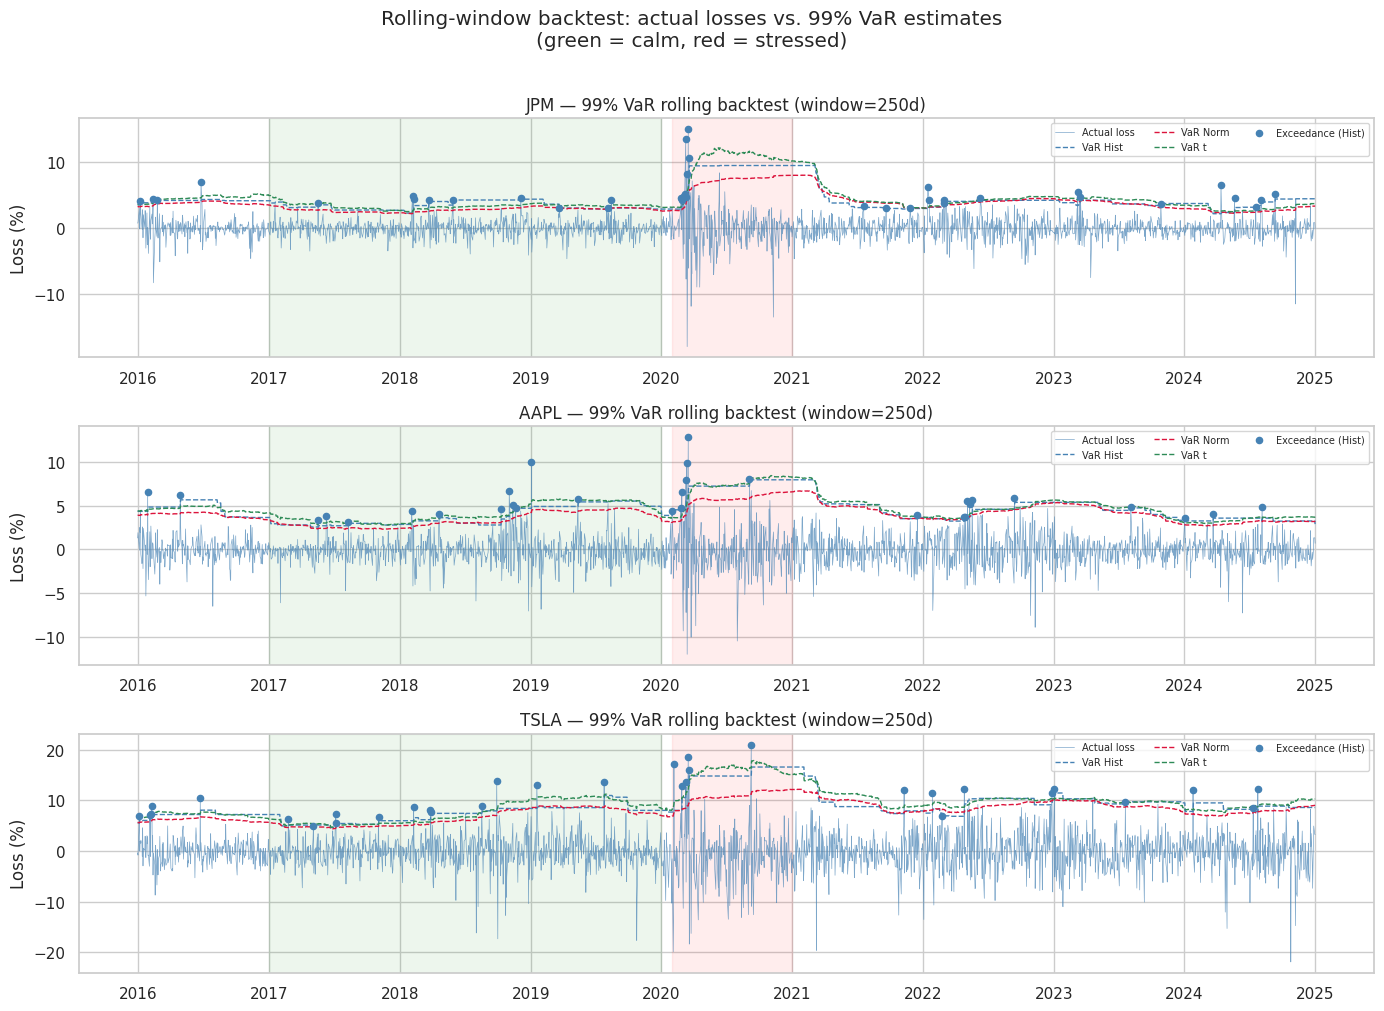

In [29]:
fig, axes = plt.subplots(len(TICKERS), 1, figsize=(14, 10), sharex=False)

for ax, ticker in zip(axes, TICKERS):
    bt = bt_results[ticker].copy()
    bt['date'] = pd.to_datetime(bt['date'])

    ax.plot(bt['date'], bt['actual_loss'] * 100, lw=0.5, color='steelblue', alpha=0.7, label='Actual loss')
    ax.plot(bt['date'], bt['var_hist'] * 100, lw=1.0, color='steelblue', ls='--', label='VaR Hist')
    ax.plot(bt['date'], bt['var_norm'] * 100, lw=1.0, color='crimson',   ls='--', label='VaR Norm')
    ax.plot(bt['date'], bt['var_t'] * 100,    lw=1.0, color='seagreen',  ls='--', label='VaR t')

    # Exceedances for historical method
    exc = bt[bt['exceed_hist'] == 1]
    ax.scatter(exc['date'], exc['actual_loss'] * 100, color='steelblue', s=20, zorder=5, label='Exceedance (Hist)')

    # Shade sub-periods
    ax.axvspan(CALM_START, CALM_END, alpha=0.07, color='green')
    ax.axvspan(STRESSED_START, STRESSED_END, alpha=0.07, color='red')

    ax.set_ylabel('Loss (%)')
    ax.set_title(f'{ticker} — 99% VaR rolling backtest (window={WINDOW}d)')
    ax.legend(fontsize=7, loc='upper right', ncol=3)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

plt.suptitle('Rolling-window backtest: actual losses vs. 99% VaR estimates\n(green = calm, red = stressed)', y=1.01)
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, '05_exceedance_timeline.png'), dpi=150, bbox_inches='tight')
plt.show()

## 4. Kupiec test results — full sample and sub-periods

In [30]:
bt_rows = []
methods = ['hist', 'norm', 't']
method_labels = {'hist': 'Historical', 'norm': 'Parametric Normal', 't': 'Parametric t'}

for ticker in TICKERS:
    bt = bt_results[ticker].copy()
    bt['date'] = pd.to_datetime(bt['date'])

    subsets = {
        'full': bt,
        'calm': bt[(bt['date'] >= CALM_START) & (bt['date'] <= CALM_END)],
        'stressed': bt[(bt['date'] >= STRESSED_START) & (bt['date'] <= STRESSED_END)],
    }

    for period, sub in subsets.items():
        for m in methods:
            col = f'exceed_{m}'
            valid = sub[col].dropna()
            n_obs    = len(valid)
            n_exceed = int(valid.sum())
            if n_obs < 10:
                continue
            kupiec = kupiec_pof_test(n_exceed, n_obs, ALPHA)
            bt_rows.append({
                'Ticker': ticker,
                'Period': period,
                'Method': method_labels[m],
                'N_obs': n_obs,
                'N_exceed': n_exceed,
                'Obs rate (%)': round(kupiec['observed_rate'] * 100, 3),
                'Exp rate (%)': round(kupiec['expected_rate'] * 100, 3),
                'LR stat': kupiec['lr_stat'],
                'p-value': kupiec['p_value'],
                'Reject H0 (5%)?': 'Yes' if kupiec['reject_5pct'] else 'No',
            })

bt_table = pd.DataFrame(bt_rows)
bt_table.to_csv(os.path.join(TAB_DIR, '05_backtesting_kupiec.csv'), index=False)
bt_table

,Ticker,Period,Method,N_obs,N_exceed,Obs rate (%),Exp rate (%),LR stat,p-value,Reject H0 (5%)?
0,JPM,full,Historical,2266,39,1.721,1.0,9.7902,0.0018,Yes
1,JPM,full,Parametric Normal,2266,51,2.251,1.0,26.4244,0.0000,Yes
2,JPM,full,Parametric t,2266,37,1.633,1.0,7.6953,0.0055,Yes
3,JPM,calm,Historical,754,9,1.194,1.0,0.2689,0.6041,No
4,JPM,calm,Parametric Normal,754,15,1.989,1.0,5.7896,0.0161,Yes
5,JPM,calm,Parametric t,754,7,0.928,1.0,0.0400,0.8414,No
6,JPM,stressed,Historical,232,10,4.310,1.0,14.1201,0.0002,Yes
7,JPM,stressed,Parametric Normal,232,15,6.466,1.0,31.3478,0.0000,Yes
8,JPM,stressed,Parametric t,232,10,4.310,1.0,14.1201,0.0002,Yes
9,AAPL,full,Historical,2266,31,1.368,1.0,2.7810,0.0954,No


## 5. Backtesting summary and interpretation

**Reading the Kupiec test:**
- H₀: The observed exceedance rate equals the nominal rate (1% for 99% VaR).
- **Reject H₀ → the model is mis-calibrated** (either too conservative or too risky to use).
- Failure to reject → exceedances are statistically consistent with 1% frequency.

**Expected pattern under heavy tails:**
- The **Normal VaR** should be rejected in stressed periods (too many exceedances, i.e., the model understated risk).
- The **Historical and Student-t VaR** should fail to reject (well-calibrated to heavy tails).

**Stressed vs. calm sub-periods:**
- Higher exceedance rates during stressed periods are expected and confirm regime-dependent tail behaviour.
- A model that is well-calibrated in calm periods but rejected in stressed periods has failed a key robustness check.

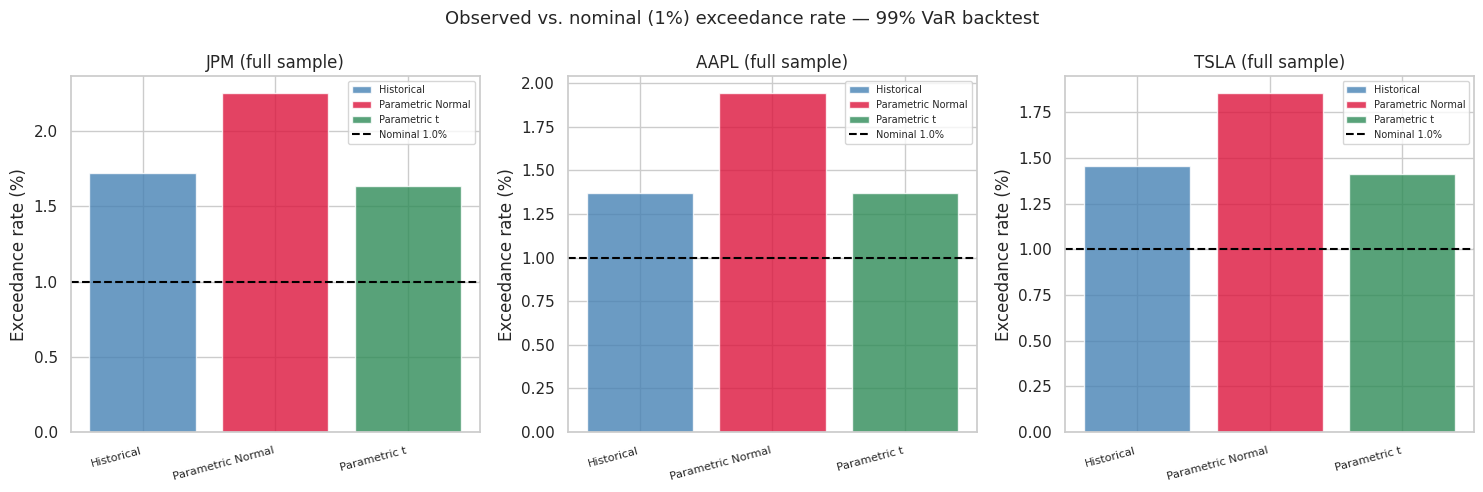

In [31]:
# Visual summary: observed vs. expected exceedance rates
fig, axes = plt.subplots(1, len(TICKERS), figsize=(15, 5))

for ax, ticker in zip(axes, TICKERS):
    sub = bt_table[(bt_table['Ticker'] == ticker) & (bt_table['Period'] == 'full')]
    x = np.arange(len(methods))
    obs_rates = [sub[sub['Method'] == method_labels[m]]['Obs rate (%)'].values[0]
                 if len(sub[sub['Method'] == method_labels[m]]) > 0 else 0
                 for m in methods]
    exp_rate = (1 - ALPHA) * 100

    bars = ax.bar(x, obs_rates, color=['steelblue', 'crimson', 'seagreen'], alpha=0.8,
                  label=[method_labels[m] for m in methods])
    ax.axhline(exp_rate, color='black', lw=1.5, ls='--', label=f'Nominal {exp_rate:.1f}%')
    ax.set_xticks(x)
    ax.set_xticklabels([method_labels[m] for m in methods], rotation=15, ha='right', fontsize=8)
    ax.set_ylabel('Exceedance rate (%)')
    ax.set_title(f'{ticker} (full sample)')
    ax.legend(fontsize=7)

plt.suptitle('Observed vs. nominal (1%) exceedance rate — 99% VaR backtest', fontsize=13)
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, '05_exceedance_rates.png'), dpi=150, bbox_inches='tight')
plt.show()

## 6. Decision-maker takeaway

> **Use the Student-t estimator for daily VaR and CVaR on individual equities at the 99% level.**  
> It correctly accounts for heavy tails (confirmed by the Jarque–Bera test and low fitted ν in Notebook 02), outperforms the Normal estimator on backtesting under market stress, and converges to the true value faster than historical simulation in short estimation windows (n ≤ 250).  
> The Normal estimator should be reserved for portfolios that are well-diversified enough to be near-Gaussian and is not appropriate for tail-risk measurement on individual equities.